# 랜딩 페이지 A/B 테스트 분석
**[통계적 검정과 인과추론] 종합 과제**

- 데이터 출처: Kaggle, *A/B Testing* (zhangluyuan) — https://www.kaggle.com/datasets/zhangluyuan/ab-testing
- 내려받은 날짜: 2026-11-06  <!-- TODO: 실제 내려받은 날짜가 다르면 수정 -->
- 데이터 파일: `ab_data.csv` (컬럼: user_id, timestamp, group, landing_page, converted)

**분석 흐름**: 0. 준비 → 1. 데이터 점검 → 2. 질문과 가설 → 3. 검정 선택 → 4. 검정·보고 → 5. 한 걸음 더 → 6. 의사결정

## 0. 준비 — 라이브러리 불러오기

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 재현성을 위해 난수 시드 고정 (5단계에서 난수를 쓸 수도 있으므로 미리 고정)
# 왜? 컴퓨터가 만드는 "랜덤"은 시드 값이 같으면 매번 같은 결과가 나옴. 시드를 고정해 두면 다른 사람이 돌려도 결과가 똑같이 나오고, 이걸 재현성이라고 해요. 
SEED = 42
np.random.seed(SEED)

plt.rcParams['font.family'] = 'Malgun Gothic'   # 그래프 한글 깨짐 방지 (Windows)
plt.rcParams['axes.unicode_minus'] = False

## 1. 데이터 점검
검정보다 먼저 합니다. 데이터가 오염돼 있으면 p값은 의미가 없습니다.

1-1 기본 확인 → 1-2 배정 일관성 → 1-3 중복 → 1-4 정제 → 1-5 SRM 점검

> ⚠️ 이 단계에서는 **그룹별 전환율을 보지 않습니다.** 가설(2단계)을 먼저 정해야 하기 때문입니다.

### 1-1. 기본 확인 — 행 수, 컬럼, 자료형, 결측치

In [2]:
df_raw = pd.read_csv('ab_data.csv')
print('행 수, 열 수:', df_raw.shape)
df_raw.head()

행 수, 열 수: (294478, 5)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [3]:
df_raw.info()        # 컬럼별 자료형과 non-null 개수

<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       294478 non-null  int64
 1   timestamp     294478 non-null  str  
 2   group         294478 non-null  str  
 3   landing_page  294478 non-null  str  
 4   converted     294478 non-null  int64
dtypes: int64(2), str(3)
memory usage: 23.0 MB


In [4]:
df_raw.isnull().sum()   # 컬럼별 결측치 개수

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64

In [5]:
# 범주형 컬럼에 어떤 값들이 있는지 확인
for col in ['group', 'landing_page', 'converted']:
    print(df_raw[col].value_counts(), '\n')

# 실험 기간
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'])
print('실험 기간:', df_raw['timestamp'].min(), '~', df_raw['timestamp'].max())

#treatment(실험군): 147,276행
#control(대조군): 147,202행
#오타나 이상한 값(Control, test 등)이 섞여 있지 않다는 걸 확인

#두 그룹 크기도 거의 같아서 반반으로 나눠진 걸 확인

#모두가 정상 배정됐다면 "treatment 수 = new_page 수"여야 함. 
# 숫자가 다르다는 건 그룹과 페이지가 어긋난 사람이 있다는 신호

#converted: 전환했나 - 그룹을 나누지 않은 전체 숫자
# 0 = 전환 안 함: 259,241행 (약 88.0%)
# 1 = 전환함(구매, 가입 등): 35,237행 (약 12.0%)

#실험은 2017년 1월 2일부터 24일까지 약 22일(3주 남짓)

group
treatment    147276
control      147202
Name: count, dtype: int64 

landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64 

converted
0    259241
1     35237
Name: count, dtype: int64 

실험 기간: 2017-01-02 13:42:05.378582 ~ 2017-01-24 13:41:54.460509


### 1-2. 배정 일관성 — 처치 라벨이 어긋난 행이 있는가?
정상이라면 `control ↔ old_page`, `treatment ↔ new_page` 조합만 있어야 합니다.

In [6]:
pd.crosstab(df_raw['group'], df_raw['landing_page'])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [7]:
mismatch = ((df_raw['group'] == 'control')   & (df_raw['landing_page'] == 'new_page')) | \
           ((df_raw['group'] == 'treatment') & (df_raw['landing_page'] == 'old_page'))
print('배정이 어긋난 행 수:', mismatch.sum())

배정이 어긋난 행 수: 3893


### 1-3. 중복 확인 — 같은 user_id가 두 번 이상 나오는가?
한 사용자는 한 번만 실험에 들어가야 합니다(관측치의 독립성).

In [8]:
print('전체 행 수     :', len(df_raw))
print('고유 user_id 수:', df_raw['user_id'].nunique())
print('중복된 user_id 수:', df_raw['user_id'].duplicated().sum())

전체 행 수     : 294478
고유 user_id 수: 290584
중복된 user_id 수: 3894


In [9]:
# 배정이 정상인 행만 남긴 뒤에도 중복이 남는지 확인
df_ok = df_raw[~mismatch]
dup_ids = df_ok.loc[df_ok['user_id'].duplicated(keep=False), 'user_id'].unique()
print('정상 배정 행 중 중복 user_id:', len(dup_ids))
df_ok[df_ok['user_id'].isin(dup_ids)].sort_values('user_id')

정상 배정 행 중 중복 user_id: 1


,user_id,timestamp,group,landing_page,converted
1899,773192,2017-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


### 1-4. 정제
**정제 규칙**
- **배정이 어긋난 행 제거** (3,893행, 전체의 1.3%) — 이유: 그룹과 실제로 본 페이지가 다르면 이 사람의 결과가 기존 페이지 효과인지 새 페이지 효과인지 알 수 없다. 남겨 두면 두 그룹의 차이가 흐려진다.
- **중복 user_id는 첫 기록만 남김** (1명) — 이유: 한 사람을 두 번 세면 그 사람의 행동이 두 배로 반영되고, "관측치는 서로 독립"이라는 검정의 전제가 깨진다. 실험에 처음 들어온 순간의 기록이 진짜 배정이므로 첫 기록을 남긴다.

In [10]:
df = df_ok.drop_duplicates(subset='user_id', keep='first').copy()

print(f'정제 전: {len(df_raw):,}행')
print(f'배정 불일치 제거 후: {len(df_ok):,}행  (-{mismatch.sum():,})')
print(f'중복 제거 후(최종): {len(df):,}행  (-{len(df_ok) - len(df):,})')
assert df['user_id'].is_unique

정제 전: 294,478행
배정 불일치 제거 후: 290,585행  (-3,893)
중복 제거 후(최종): 290,584행  (-1)


### 1-5. SRM 점검 — 배정 비율이 50:50인가?
⚠️ 여기서는 **p가 커야 정상**입니다(= 의도한 50:50과 다르지 않다). 평소 검정과 해석 방향이 반대입니다.

In [11]:
n_a = (df['group'] == 'control').sum()
n_b = (df['group'] == 'treatment').sum()
print(f'control: {n_a:,} ({n_a/(n_a+n_b):.2%}),  treatment: {n_b:,} ({n_b/(n_a+n_b):.2%})')

srm = stats.chisquare([n_a, n_b], [(n_a + n_b) / 2] * 2)
print(f'SRM 카이제곱 = {srm.statistic:.3f}, p = {srm.pvalue:.4f}')

control: 145,274 (49.99%),  treatment: 145,310 (50.01%)
SRM 카이제곱 = 0.004, p = 0.9468


**1단계 정리**
- **정제 전 → 후 행 수**: 294,478행 → **290,584행** (배정 불일치 3,893행, 중복 1행 제거). 최종 행 수가 고유 사용자 수(290,584명)와 같으므로 이제 **1인 1행**이다.
- **SRM 결과 해석**: control 145,274명(49.99%) vs treatment 145,310명(50.01%), χ² = 0.004, p = 0.947. p가 매우 크므로 "의도한 50:50과 다르다"는 증거가 없다. → 배정 시스템은 정상이고, 데이터를 믿고 다음 단계로 넘어갈 수 있다.

## 2. 질문과 가설 정하기
⚠️ **결과를 보기 전에** 정하고, 끝까지 바꾸지 않습니다.

- **질문 (한 문장)**: 새 랜딩 페이지로 바꾸면 기존 페이지와 비교해 전환율이 달라질까?
- **H0 (귀무가설)**: 새 페이지의 전환율과 기존 페이지의 전환율은 같다. (p_new = p_old)
- **H1 (대립가설)**: 새 페이지의 전환율과 기존 페이지의 전환율은 다르다. (p_new ≠ p_old)
- **유의수준 α**: 0.05
- **단측 / 양측**: **양측** — 선택한 이유: 새 페이지가 전환율을 **떨어뜨릴** 가능성도 사업적으로 꼭 알아야 하는 정보다. 단측("새 페이지가 더 크다")으로 정하면 새 페이지가 나빠진 경우를 잡아내지 못한다. 결과를 보기 전이라 방향을 장담할 근거도 없으므로 더 보수적인 양측을 고른다.

> 💡 **용어 풀이**
> - **귀무가설(H0)**: "차이가 없다"는 기본 입장. 검정은 이 입장을 뒤집을 만큼 증거가 충분한지 확인하는 과정이다.
> - **대립가설(H1)**: 우리가 증거를 찾고 싶은 주장. 여기서는 "차이가 있다".
> - **유의수준 α = 0.05**: 실제로는 차이가 없는데 "있다"고 잘못 결론 낼 위험을 5%까지만 허용하겠다는 약속. p값이 0.05보다 작으면 H0를 기각한다.

In [12]:
ALPHA = 0.05                 # 2단계에서 정한 유의수준
ALTERNATIVE = 'two-sided'    # 양측 검정 (새 페이지가 좋아지는 경우와 나빠지는 경우를 모두 본다)

## 3. 검정 고르기 ⭐
아래 세 질문에 답해 보세요.
1. 성공 지표(`converted`)는 비율인가, 연속형인가? → **비율.** `converted`는 0(전환 안 함)과 1(전환함)만 있는 이진 변수라서, 그룹별 평균이 곧 전환율(%)이다.
2. 비교할 집단은 몇 개인가? → **2개** (control = 기존 페이지, treatment = 새 페이지)
3. (연속형일 때만) 정규성·등분산 가정은? → **해당 없음.** 연속형이 아니므로 t검정용 가정은 따지지 않는다. 대신 비율 검정의 조건인 "표의 각 칸 기대도수가 5 이상"을 확인한다. 칸마다 수만 명이라 충분하다(4-2에서 확인).

**나는 카이제곱 독립성 검정(2×2 분할표)을 골랐다. 왜냐하면** 성공 지표가 "전환했다/안 했다"로 나뉘는 범주형 결과이고, 비교할 집단이 두 개이기 때문이다. 이 검정은 "그룹(기존/새 페이지)과 전환 여부가 서로 관련이 있는가?", 즉 "두 그룹의 전환율이 같은가?"를 묻는다. 데이터를 그룹 2개 × 결과 2개의 표로 정리할 수 있어 구조가 정확히 맞는다. 같은 질문을 **두 비율 z검정**으로도 풀 수 있는데, 2×2 표에서는 두 검정이 수학적으로 같은 답을 준다(z² = χ²). 표본이 각 그룹 14만 명이 넘을 만큼 크므로 근사 검정의 조건도 넉넉히 만족한다. 표본이 이렇게 크면 연속성 보정은 결과에 거의 영향이 없으므로 보정 없이(`correction=False`) 계산해 z검정과 결과를 맞춘다.

## 4. 검정 수행과 3종 세트 보고
① 점추정(차이) ② 95% 신뢰구간 ③ 효과 크기를 함께 적습니다. 비율이면 절대 차이(%p)와 상대 차이(%)를 둘 다 적습니다.

### 4-1. 그룹별 전환율 (요약)

In [13]:
# 그룹별 사용자 수, 전환 수, 전환율
summary = (df.groupby('group')['converted']
             .agg(사용자수='count', 전환수='sum', 전환율='mean')
             .loc[['control', 'treatment']])
summary.style.format({'사용자수': '{:,}', '전환수': '{:,}', '전환율': '{:.2%}'})

,사용자수,전환수,전환율
group,,,
control,"145,274","17,489",12.04%
treatment,"145,310","17,264",11.88%


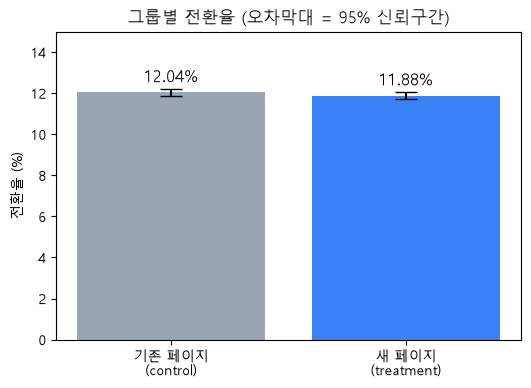

In [14]:
# 그룹별 전환율 막대그래프 (오차막대 = 95% 신뢰구간)
rate = summary['전환율']
se = np.sqrt(rate * (1 - rate) / summary['사용자수'])   # 비율의 표준오차

fig, ax = plt.subplots(figsize=(6, 4))
labels = ['기존 페이지\n(control)', '새 페이지\n(treatment)']
ax.bar(labels, rate * 100, yerr=1.96 * se * 100, capsize=8, color=['#9aa5b1', '#3b82f6'])
for i, v in enumerate(rate * 100):
    ax.text(i, v + 0.5, f'{v:.2f}%', ha='center', fontsize=12)
ax.set_ylim(0, 15)
ax.set_ylabel('전환율 (%)')
ax.set_title('그룹별 전환율 (오차막대 = 95% 신뢰구간)')
plt.show()

> 💡 **결과 읽기 (4-1)**
> - 기존 페이지 전환율은 **12.04%**(145,274명 중 17,489명), 새 페이지는 **11.88%**(145,310명 중 17,264명)이다.
> - 눈으로 보면 새 페이지가 오히려 **0.16%p 낮다.** 하지만 이 정도 차이는 무작위로 사람을 나눌 때 우연히도 생길 수 있다. 우연인지 아닌지는 4-2의 검정으로 판단한다.
> - 그래프의 y축을 0부터 시작했기 때문에 두 막대가 거의 같아 보인다. 이게 정직한 그림이다. y축을 11.5~12.5%처럼 잘라서 그리면 작은 차이가 크게 부풀려 보이니 조심한다.

### 4-2. 검정 수행

In [15]:
# 2×2 분할표: 행 = 그룹, 열 = 전환 여부(0/1)
table = pd.crosstab(df['group'], df['converted'])
print('[분할표]')
print(table, '\n')

assert ALTERNATIVE == 'two-sided'   # 카이제곱 검정은 원래 양측 검정이다
chi2, p_value, dof, expected = stats.chi2_contingency(table, correction=False)
print(f'기대도수 최솟값: {expected.min():,.0f}  (5 이상이면 검정 조건 충족)')
print(f'χ²({dof}) = {chi2:.3f}, p = {p_value:.4f}')

# 같은 질문을 두 비율 z검정으로 풀어 보기 (z² = χ² 인지 확인)
n_a, x_a = table.loc['control'].sum(),   table.loc['control', 1]
n_b, x_b = table.loc['treatment'].sum(), table.loc['treatment', 1]
p_pool = (x_a + x_b) / (n_a + n_b)
z = (x_b / n_b - x_a / n_a) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
print(f'(참고) 두 비율 z검정: z = {z:.3f}, z² = {z**2:.3f}, p = {2 * stats.norm.sf(abs(z)):.4f}')

print('\n결론:', 'p < α → H0 기각 (전환율에 차이가 있다)' if p_value < ALPHA
      else 'p ≥ α → H0를 기각하지 못함 (전환율이 다르다는 증거가 부족하다)')

[분할표]
converted       0      1
group                   
control    127785  17489
treatment  128046  17264 

기대도수 최솟값: 17,374  (5 이상이면 검정 조건 충족)
χ²(1) = 1.719, p = 0.1899
(참고) 두 비율 z검정: z = -1.311, z² = 1.719, p = 0.1899

결론: p ≥ α → H0를 기각하지 못함 (전환율이 다르다는 증거가 부족하다)


> 💡 **결과 읽기 (4-2)**
> - **분할표**: 그룹별로 전환 안 한 사람(0)과 전환한 사람(1)의 수를 센 표다. 카이제곱 검정은 이 표를 재료로 쓴다.
> - **기대도수**: "두 그룹의 전환율이 정말 같다면 각 칸에 몇 명이 있어야 하는가"를 계산한 값이다. 가장 작은 칸도 수만 명이라 검정 조건(5 이상)을 넉넉히 만족한다.
> - **χ²(1) = 1.72**: 실제 표와 기대한 표가 얼마나 다른지를 숫자 하나로 나타낸 값이다. 클수록 차이가 크다. 괄호 안의 1은 자유도로, 2×2 표에서는 항상 1이다.
> - **p = 0.190**: "정말로 차이가 없다면, 이 정도 이상의 차이가 우연히 나올 확률이 19%"라는 뜻이다. 우리가 정한 기준 α = 0.05보다 크므로 **H0를 기각하지 못한다.**
> - z검정으로 풀어도 z² = χ², p값이 똑같이 나온다. 같은 질문을 다른 방식으로 계산했을 뿐이다.
>
> ⚠️ "H0를 기각하지 못했다"는 "두 페이지가 똑같다고 증명했다"는 뜻이 **아니다.** "다르다고 말할 증거가 부족하다"는 뜻이다. 차이가 얼마나 작을 수 있는지는 4-3의 신뢰구간과 5단계에서 확인한다.

### 4-3. 점추정 · 95% 신뢰구간 · 효과 크기

In [16]:
p_a, p_b = x_a / n_a, x_b / n_b          # 기존 / 새 페이지 전환율

# ① 점추정: 차이
diff = p_b - p_a                          # 절대 차이 (새 - 기존)
rel = diff / p_a                          # 상대 차이 (기존 대비 몇 % 변했나)

# ② 95% 신뢰구간 (두 비율 차이의 Wald 구간)
se_diff = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
z_crit = stats.norm.ppf(1 - ALPHA / 2)    # 1.96
ci_low, ci_high = diff - z_crit * se_diff, diff + z_crit * se_diff

# ③ 효과 크기: Cohen's h (비율 차이용, 0.2 작음 / 0.5 중간 / 0.8 큼)
cohen_h = 2 * np.arcsin(np.sqrt(p_b)) - 2 * np.arcsin(np.sqrt(p_a))

print(f'전환율: 새 페이지 {p_b:.2%} vs 기존 페이지 {p_a:.2%}')
print(f'① 절대 차이 = {diff * 100:+.2f}%p,  상대 차이 = {rel:+.2%}')
print(f'② 95% 신뢰구간 = [{ci_low * 100:+.2f}%p, {ci_high * 100:+.2f}%p]')
print(f"③ 효과 크기 Cohen's h = {cohen_h:.4f}")

전환율: 새 페이지 11.88% vs 기존 페이지 12.04%
① 절대 차이 = -0.16%p,  상대 차이 = -1.31%
② 95% 신뢰구간 = [-0.39%p, +0.08%p]
③ 효과 크기 Cohen's h = -0.0049


> 💡 **결과 읽기 (4-3)**: p값은 "차이가 있느냐 없느냐"만 알려 준다. **차이가 얼마나 큰지**는 아래 세 가지로 본다.
> - **① 점추정**: 새 페이지가 **0.16%p 낮다.** 상대적으로는 기존 전환율의 **1.3% 감소**다.
>   - **%p(퍼센트포인트)**: 전환율끼리 그냥 뺀 값 (11.88% − 12.04% = −0.16%p)
>   - **%(상대 차이)**: 기존 대비 몇 % 변했는지 (−0.16 ÷ 12.04 ≈ −1.3%)
> - **② 95% 신뢰구간 [−0.39%p, +0.08%p]**: 진짜 차이는 이 범위 어딘가에 있을 것으로 보인다.
>   - 구간 안에 **0이 들어 있으므로** "차이가 없다"는 가능성을 배제할 수 없다. 4-2의 p > 0.05와 같은 결론이다.
>   - 가장 낙관적으로 봐도 새 페이지는 **0.08%p**밖에 개선하지 못하고, 가장 비관적이면 **0.39%p** 떨어뜨린다. 구간의 대부분이 마이너스 쪽에 있다.
> - **③ Cohen's h = −0.005**: "작은 효과"의 기준선인 0.2보다도 **40배 작다.** 실질적으로 효과가 없다고 봐도 되는 수준이다.

**보고 문장**
> 새 페이지의 전환율은 **11.88% vs 12.04%** (차이 **−0.16%p**, 상대 **−1.31%**), 95% CI **[−0.39%p, +0.08%p]**, **χ²(1) = 1.72, p = 0.190**, 효과 크기 **Cohen's h = −0.005**. 유의수준 0.05에서 두 페이지의 전환율이 다르다는 증거는 없다.

## 5. 한 걸음 더 — 1개 선택
- A. 검정력과 MDE (이 실험은 효과를 잡을 힘이 있었나?)
- B. 가정이 깨졌다면 (연속형 지표용 — 이 데이터엔 잘 맞지 않음)
- C. 세그먼트(요일·시간대) 반복 검정 + 다중검정 보정
- D. 비용까지 따져 보기

**선택: A. 검정력과 MDE** — 이유: 결과가 "유의하지 않음"으로 나왔다. 이때 꼭 따져야 할 것은 **"정말 효과가 없어서인가, 아니면 실험 규모가 작아서 효과를 놓친 것인가?"**이다. 실험이 어느 크기의 차이까지 잡아낼 수 있었는지(MDE)를 계산하면, "유의하지 않음"을 얼마나 믿어도 되는지 알 수 있다.

> 💡 **용어 풀이**
> - **검정력(power)**: 진짜 효과가 있을 때 검정이 그걸 제대로 잡아낼 확률. 보통 80%를 목표로 한다.
> - **MDE(최소 검출 효과, Minimum Detectable Effect)**: 이 실험 규모(표본 수)로 검정력 80%를 내며 잡아낼 수 있는 **가장 작은 차이**. 진짜 효과가 MDE보다 작으면 실험이 놓칠 가능성이 크다.

In [17]:
POWER = 0.80                                   # 목표 검정력
z_alpha = stats.norm.ppf(1 - ALPHA / 2)        # 1.96 (양측 α = 0.05)
z_beta = stats.norm.ppf(POWER)                 # 0.84

# 두 그룹의 크기가 거의 같으므로 그룹당 n_a명, 기준 전환율 p_a로 근사
se0 = np.sqrt(2 * p_a * (1 - p_a) / n_a)

# ① MDE: 이 실험이 80% 확률로 잡아낼 수 있는 가장 작은 차이
mde = (z_alpha + z_beta) * se0
print(f'① MDE = {mde * 100:.2f}%p  (상대 {mde / p_a:.1%})')

# ② 관측된 차이가 진짜 효과라면, 이 실험이 그것을 잡아낼 확률
power_obs = stats.norm.sf(z_alpha - abs(diff) / se0) + stats.norm.cdf(-z_alpha - abs(diff) / se0)
print(f'② 관측 차이 {abs(diff) * 100:.2f}%p에 대한 검정력 = {power_obs:.1%}')

# ③ 관측된 차이를 검정력 80%로 잡으려면 그룹당 몇 명이 필요한가
n_needed = (z_alpha + z_beta) ** 2 * 2 * p_a * (1 - p_a) / diff ** 2
days = (df['timestamp'].max() - df['timestamp'].min()).days
per_day = n_a / days                            # 그룹당 하루 유입 인원
print(f'③ 필요 표본: 그룹당 약 {n_needed:,.0f}명 (현재 {n_a:,}명의 {n_needed / n_a:.1f}배)')
print(f'   지금 속도(그룹당 하루 약 {per_day:,.0f}명)라면 약 {n_needed / per_day:,.0f}일이 걸린다')

① MDE = 0.34%p  (상대 2.8%)
② 관측 차이 0.16%p에 대한 검정력 = 25.7%
③ 필요 표본: 그룹당 약 667,362명 (현재 145,274명의 4.6배)
   지금 속도(그룹당 하루 약 6,918명)라면 약 96일이 걸린다


> 💡 **결과 읽기 (5단계)**
> - **① MDE = 0.34%p (상대 약 2.8%)**: 이 실험은 전환율이 0.34%p 이상 달라졌다면 80% 확률로 잡아낼 수 있었다. 랜딩 페이지 개편에서 기대할 만한 개선(보통 상대 5~10%)보다 훨씬 작은 차이까지 볼 수 있는, **충분히 큰 실험**이었다.
> - **② 관측 차이에 대한 검정력 ≈ 26%**: 실제 차이가 정말 0.16%p라면 이 실험이 잡아낼 확률은 4번 중 1번 정도다. 그만큼 관측 차이가 작다는 뜻이다.
>   (주의: 이 값은 "검정력이 낮았으니 결과를 무시하자"는 근거로 쓰면 안 된다. 관측된 p값에서 거의 자동으로 계산되는 값이라 새로운 정보가 거의 없다. 판단은 ①의 MDE와 4-3의 신뢰구간으로 한다.)
> - **③ 필요 표본 ≈ 그룹당 67만 명 (지금의 약 4.6배, 약 96일)**: 0.16%p 차이를 확실히 잡으려면 실험을 몇 달 더 돌려야 한다. 그런데 그 차이는 **새 페이지가 더 나쁜 방향**이고, 신뢰구간상 가장 좋은 경우도 +0.08%p뿐이다. 오래 기다려서 얻을 수 있는 최선이 "아주 조금 나쁘거나 거의 같다"이므로 **추가로 실험할 가치가 낮다.**
>
> **결론**: 실험 규모는 의미 있는 효과를 잡기에 충분했다. 그런데도 효과를 찾지 못했으므로 "새 페이지는 의미 있는 개선을 만들지 못했다"는 결론을 꽤 믿을 수 있다.

## 6. 의사결정
1. **질문과 가설** — "새 랜딩 페이지로 바꾸면 전환율이 달라질까?" H0: 두 페이지의 전환율이 같다 / H1: 다르다. α = 0.05, 양측 검정(새 페이지가 나빠질 가능성도 봐야 하므로). 결과를 보기 전에 정했다.
2. **데이터 위생 점검** — 294,478행 → **290,584행**. 그룹과 페이지가 어긋난 3,893행(1.3%)과 중복 사용자 1명을 제거해 1인 1행으로 만들었다. 결측치는 없었다. SRM 점검(p = 0.947) 결과 50:50 배정이 정상적으로 이루어졌다.
3. **검정 선택 근거** — 성공 지표가 0/1 이진 변수(비율)이고 비교 집단이 2개이므로 **카이제곱 독립성 검정(2×2)**을 썼다. 두 비율 z검정과 같은 결과(z² = χ²)임을 확인했다. 칸별 기대도수가 수만 명이라 근사 조건을 충족한다.
4. **결과** — 새 페이지 11.88% vs 기존 12.04%, 차이 **−0.16%p**(상대 −1.31%), 95% CI **[−0.39%p, +0.08%p]**, χ²(1) = 1.72, **p = 0.190**, Cohen's h = −0.005. 통계적으로 유의하지 않고, 효과 크기도 사실상 0이다.
5. **의사결정** — **출시하지 않음 (기존 페이지 유지).** 근거: ① 새 페이지가 낫다는 증거가 없다(p = 0.19). ② 점추정은 오히려 마이너스이고, 신뢰구간의 가장 좋은 경우도 +0.08%p로 실무적으로 의미 없는 크기다. ③ 실험은 0.34%p 차이까지 잡을 수 있을 만큼 컸으므로 "표본이 작아서 놓쳤다"고 보기 어렵다. ④ 데이터를 더 모으려면 4.6배(약 96일, 3개월 이상) 걸리는데, 기대할 수 있는 최선이 "거의 같음"이라 추가 수집도 권하지 않는다. 페이지 교체에 드는 비용과 위험을 감수할 이유가 없다.
6. **한계** —
   - **실험 기간이 약 3주로 짧다.** 사용자가 새 디자인에 처음엔 낯설어하다가 익숙해지는 효과(변화 거부)나, 반대로 처음에만 신기해하는 효과(신기 효과)는 이 기간으로 구분할 수 없다.
   - **전환 여부(0/1)만 봤다.** 구매 금액, 재방문, 이탈률 같은 다른 지표에서는 차이가 있을 수 있다.
   - **제거한 3,893행이 무작위로 생긴 오류라고 가정했다.** 특정 유형의 사용자에게 몰려서 생긴 오류라면 결과가 치우칠 수 있다.
   - **기기, 신규/기존 고객 같은 세그먼트 정보가 없다.** 전체로는 차이가 없어도 특정 집단에서는 효과가 있을 수 있는데, 이 데이터로는 알 수 없다.
   - **2017년 1월 데이터다.** 계절이나 현재 사용자 특성이 다르면 같은 결과가 나온다고 장담할 수 없다.